# Accuracy of PyToF

How accurate are the results of PyToF, and how do we know? This notebook compares PyToF with exact solutions and independent literature results. **One notebook, two modes**, chosen by `MODE` in the first code cell (or by the environment variable `ACCURACY_MODE`):

| mode | run time | what |
|---|---|---|
| `"quick"` | ~10 s | analytical checks, Bessel sweep for $N = 2^5 \ldots 2^{12}$, DR2 against CMS, comparison with the shipped error tables |
| `"full"` | ~4 min on 20 cores | everything for $N = 2^3 \ldots 2^{15}$, all binnings, Simpson *and* trapezoid rule, DR2 and DR3, the code of Movshovitz & Fortney (2022); regenerates `images/` |

The studies:

1. **Analytical checks**: normalized moment of inertia of three exact bodies, Love functions $K_n$ of three density profiles (Gavrilov, Zharkov & Leontev 1976) and of a two-layer planet (Consorzi, Melini & Spada 2023, Eq. 2).
2. **Gravitational moments** of the Wisdom & Hubbard (2016) Jupiter polytrope ($\rho=\sqrt{P}$, $m=0.089195487$) against its exact Bessel-function solution, as a function of $N$ and the order (full: also the binning $N/n_\mathrm{bin}$ and Movshovitz & Fortney 2022).
3. **Differential rotation** against the CMS results of Wisdom & Hubbard (2016) (quick: DR2 at $N=2048$; full: DR2 and DR3 for all $N$).
4. **The error tables** shipped with the package (`PyToF/accuracy_data_*.npz`, used by `ToF.get_Js_errors()`) are recomputed and compared: a deviation of 0 means the tables belong to the current code.

All literature numbers and their citations are in [`references.py`](references.py); the test suite uses the same file.

**Efficiency.** Every PyToF run of every study goes into *one* process pool, the most expensive runs first (no idle cores while the last big run finishes), with one BLAS thread per worker. Each run is computed once: the unbinned Simpson sweep is the first column of the binning sweep and also the source of the error tables.

**The mean radius.** PyToF's `R_eq_to_R_m` is relative to the *volume-equivalent* radius `X.li[0]`. The reference of Wisdom & Hubbard (2016) writes the surface as $r = R\,s\,[1+\eta(s,\mu)]$ with $\eta=\sum_{l>0}a_lP_l(\mu)$ (their Eqs. 3-5: no $P_0$ term), i.e. relative to the *angular mean* radius $R = R_\mathrm{m}(1+s_0)$. All radius ratios below are therefore $R_\mathrm{eq}/R$ = `X.R_eq_to_R_m / (1 + s0)` with `s0 = X.figure_functions[0][0]`; see notebook 1 of the tutorial.

In [1]:
import os
import sys
import time
import multiprocessing
from pathlib import Path

# one BLAS/OpenMP thread per worker; must be set before numpy is imported
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")

import numpy as np
import matplotlib.pyplot as plt

# --- settings ---------------------------------------------------------------
MODE = os.environ.get("ACCURACY_MODE", "full")  # "quick" or "full"
PROCESSES = None  # worker processes; None: all cores
WRITE_TABLES = False  # full only: True overwrites PyToF/accuracy_data_*.npz with this run
SAVE_FIGURES = MODE == "full"  # write the figures to images/
# ---------------------------------------------------------------------------
assert MODE in ("quick", "full")
FULL = MODE == "full"

HERE = Path.cwd().resolve()
if not (HERE / "references.py").exists():  # opened from the repository root
    HERE = HERE / "accuracy"
ROOT = HERE.parent
sys.path.insert(0, str(HERE))
sys.path.insert(0, str(ROOT))
IMAGES = HERE / "images"
if SAVE_FIGURES:
    IMAGES.mkdir(exist_ok=True)

import references
from PyToF import ToF

ORDERS = (4, 7, 10)
KEYS = {4: "04", 7: "07", 10: "10"}
J_LABELS = [r"$R_{eq}/R$"] + [rf"$J_{{{2 * i}}}$" for i in range(1, 11)]
COLORS = {4: "C0", 7: "C1", 10: "C2"}  # default matplotlib colour cycle, one per order
RADIUS = references.JUPITER_RADIUS
print(f"mode: {MODE}, {PROCESSES or os.cpu_count()} processes")

mode: full, 20 processes


## Running PyToF and the comparison code

`run_pytof` is one calculation of the polytrope (it returns time per iteration, $R_\mathrm{eq}/R$ and $J_2 \ldots J_{2\,\mathrm{order}}$, number of iterations); `run_movshovitz` the same with the code of Movshovitz & Fortney (2022) (folder `nmovshov_ToFPlanet`). `run_all` executes a list of jobs in one pool, most expensive first.

In [2]:
def run_pytof(N, n_bin, order, alphas=None, use_simpson=True):
    """
    W&H 2016 Jupiter polytrope. Returns (time per iteration, [R_eq/R_mean, J2..J2*order], iterations).

    R_mean is the angular mean of the surface radius, the definition of the
    Bessel reference. PyToF's own R_m (X.R_eq_to_R_m) is the volume-equivalent
    radius, R_eq/R_mean = X.R_eq_to_R_m / (1 + s0) with s0 the P_0 coefficient
    of the surface figure function (see references.py, Bessel).
    """
    from PyToF import ToF

    if n_bin < 4:
        return np.nan, np.full(order + 1, np.nan), np.nan
    X = ToF(
        N=N,
        n_bin=n_bin,
        order=order,
        alphas=np.zeros(12) if alphas is None else alphas,
        verbosity=0,
        R_ref=RADIUS,
        use_simpson=use_simpson,
    )
    X.set_barotrope(lambda P, param: np.sqrt(P))
    tic = time.perf_counter()
    it = X.relax_to_barotrope()
    toc = time.perf_counter()
    s0 = X.figure_functions[0][0]
    return (toc - tic) / it, np.hstack([X.R_eq_to_R_m / (1 + s0), X.Js[1:]]), it


def run_movshovitz(N, order):
    """Same problem with the code of Movshovitz & Fortney (2022) (folder nmovshov_ToFPlanet)."""
    sys.path.insert(0, str(ROOT / "nmovshov_ToFPlanet"))
    import TOFPlanet

    res = TOFPlanet.TOFPlanet(
        N=N, nx=-1, toforder=order, dJtol=1e-10, drottol=1e-10,
        drhotol=1e-10, MaxIterHE=2, MaxIterBar=100, verbosity=0,
    )  # fmt: skip
    res.G = 6.6738480e-11
    res.GM = 126686536.1 * 1000**3
    res.mass = res.GM / res.G
    res.radius = RADIUS
    res.period = 2 * np.pi / np.sqrt(res.GM * 0.089195487 / res.radius**3)
    res.P0 = 0
    res.si = res.radius * np.linspace(1, 1 / N, N)
    res.rhoi = np.ones(N) * res.mass / (4 * np.pi / 3 * res.radius**3)
    res.set_barotrope(lambda P: np.sqrt(P))
    tic = time.perf_counter()
    it = res.relax_to_barotrope()
    toc = time.perf_counter()
    return (toc - tic) / it, np.hstack([res.aos, res.Js[1:]]), it


def _task(job):
    key, kind, args = job
    return key, (run_pytof if kind == "pytof" else run_movshovitz)(*args)


def run_all(jobs, processes, label):
    """
    jobs: list of (key, kind, args). Runs them in one pool, most expensive first
    (cost ~ N, binning divides it), returns {key: result}.
    """

    def cost(job):
        _, kind, a = job
        if kind != "pytof":  # Movshovitz & Fortney: slow at large N, start first
            return -1e18 * a[0]
        return -(a[1] * a[2])

    jobs = sorted(jobs, key=cost)
    out = {}
    tic = time.perf_counter()
    ctx = multiprocessing.get_context("fork")
    with ctx.Pool(processes) as pool:
        for i, (key, res) in enumerate(pool.imap_unordered(_task, jobs), 1):
            out[key] = res
            if i % 50 == 0 or i == len(jobs):
                print(
                    f"\r  {label}: {i}/{len(jobs)} runs, {time.perf_counter() - tic:.0f} s",
                    end="",
                    flush=True,
                )
    print()
    return out

## 1 · Analytical checks

*Moment of inertia.* A sphere of constant density ($I/MR^2 = 2/5$), a sphere with density decreasing linearly to zero at the surface ($4/15$) and a rotating spheroid of constant density (a Maclaurin spheroid), for which $I/(M R_\mathrm{eq}^2)$ is $\frac25 (R_\mathrm{eq}/R_\mathrm{m})^2$ with PyToF's own (volume-equivalent) $R_\mathrm{m}$.

*Love functions.* The linear, quadratic and polytropic density profiles of Gavrilov, Zharkov and Leontev (1976) have analytical (or rapidly converging series) solutions of the Love function $K_n(r)$ (`references.love_cases`). We list the largest deviation of $K_n r^n$ for $n = 2 \ldots 7$ at $N = 1024$.

In [3]:
def analytical_checks():
    from scipy.integrate import trapezoid

    from PyToF import ToF

    print("\n1. Analytical checks")
    N = 2**10
    radius = 1e6
    radii = radius * np.linspace(1, 1e-3, N)
    cases = [
        ("constant-density sphere, I/MR^2", 1000 * np.ones(N), np.inf, references.NMOI_SPHERE_CONSTANT_DENSITY),
        ("linear-density sphere, I/MR^2", np.linspace(0, 1000, N), np.inf, references.NMOI_SPHERE_LINEAR_DENSITY),
        ("Maclaurin spheroid, I/(M R_eq^2)", 1000 * np.ones(N), 24 * 3600, None),
    ]  # fmt: skip
    rows = []
    for name, dens, period, exact in cases:
        mass = -4 * np.pi * trapezoid(dens * radii**2, radii)
        X = ToF(N=N, M_phys=mass, R_phys=[radius, "mean"], Period=period, R_ref=radius)
        X.li, X.rhoi = radii, dens
        X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)
        X.relax_to_shape()
        if exact is None:
            exact = 2 / 5 * X.R_eq_to_R_m**2
        rows.append((name, X.get_NMoI(), exact))
    print(f"  {'':36s}{'PyToF':>10s}{'exact':>10s}{'rel. diff.':>12s}")
    for name, v, e in rows:
        print(f"  {name:36s}{v:10.6f}{e:10.6f}{abs(v / e - 1):12.1e}")

    rho_mean, radius, G = 1326.0, 70e6, 6.6738480e-11
    love = {}
    for name, case in references.love_cases(rho_mean, radius, G).items():
        r_ = radius * np.linspace(0.01, 1, N)
        mass = 4 * np.pi * trapezoid(case["rho"](r_) * r_**2, r_)
        X = ToF(N=N, M_phys=mass, R_phys=[radius, "mean"], Period=np.inf, G=G, R_ref=radius)
        X.li, X.rhoi = r_[::-1], case["rho"](r_[::-1])
        X.m_rot_calc = 0.0
        X.relax_to_shape()
        dev = {}
        for n in range(2, 8):
            r, _, K = X.get_Kn(n)
            dev[n] = (r / radius, np.abs(K * (r / radius) ** n - case["K"](r, n)))
        love[name] = dev
    print("  Love function K_n r^n: max |PyToF - analytical| (N = 1024)")
    print(f"  {'':12s}" + "".join(f"{'n=' + str(n):>10s}" for n in range(2, 8)))
    for name, dev in love.items():
        print(f"  {name:12s}" + "".join(f"{np.nanmax(dev[n][1]):10.1e}" for n in range(2, 8)))
    return rows, love

rows, love = analytical_checks()


1. Analytical checks


                                           PyToF     exact  rel. diff.
  constant-density sphere, I/MR^2       0.400000  0.400000     1.0e-09
  linear-density sphere, I/MR^2         0.266667  0.266667     4.0e-09
  Maclaurin spheroid, I/(M R_eq^2)      0.406468  0.406468     8.5e-10


  Love function K_n r^n: max |PyToF - analytical| (N = 1024)
                     n=2       n=3       n=4       n=5       n=6       n=7
  linear         8.5e-07   4.6e-07   4.0e-07   3.5e-07   3.1e-07   2.8e-07
  quadratic      2.0e-06   1.2e-06   9.3e-07   7.7e-07   6.6e-07   5.8e-07
  polytropic     2.7e-06   8.2e-07   4.1e-07   2.6e-07   1.8e-07   1.3e-07


## 2 · Sweeps: the polytrope against the Bessel solution

The job list. `quick`: Simpson's rule, no binning, $N = 2^5 \ldots 2^{12}$, plus DR2 at $N=2048$. `full`: $N = 2^3 \ldots 2^{15}$, binning factors $N/n_\mathrm{bin} = 2^0 \ldots 2^{13}$ (`n_bin < 4` is skipped), Simpson *and* trapezoid rule, DR2 and DR3 without binning, and Movshovitz & Fortney for orders 4 and 7.

In [4]:
def collect(results, Ns, steps, orders, tag):
    """results[(tag, order, iN, iS)] -> dict order -> dict(res[N, J, step], time[N, step])."""
    out = {}
    for o in orders:
        res = np.array([[results[(tag, o, i, j)][1] for j in range(len(steps))] for i in range(len(Ns))])
        tm = np.array([[results[(tag, o, i, j)][0] for j in range(len(steps))] for i in range(len(Ns))])
        out[o] = dict(res=res.transpose(0, 2, 1), time=tm)
    return out


def rel_err(res, ref):
    return np.abs((res - ref) / res)


def error_tables(Ns, steps, sweep, reference=references.Bessel):
    """The format of PyToF/accuracy_data_*.npz (used by ToF.get_Js_errors())."""
    data = {"Ns_n_bins": np.array([(int(N), int(N / s)) for N in Ns for s in steps]).astype(int)}
    for o in ORDERS:
        data[f"rel_error_{KEYS[o]}"] = rel_err(sweep[o]["res"][:, 1:, :], reference[1 : o + 1][None, :, None])
    return data


def compare_with_shipped(name, tables, mask=None):
    old = np.load(ROOT / "PyToF" / f"accuracy_data_{name}.npz")
    worst = 0.0
    for k in ("rel_error_04", "rel_error_07", "rel_error_10"):
        new, o = tables[k], old[k]
        both = np.isfinite(new) & np.isfinite(o)
        if mask is not None:
            both &= mask[(slice(None), None, slice(None))] if mask.ndim == 2 else mask
        worst = max(worst, float(np.max(np.abs(new[both] / o[both] - 1))))
    return worst


def summary(Ns, sweep, ref):
    """What a user wants: error floor per order and N needed for a target error."""
    print(
        "\n   Summary (Simpson, no binning): relative error of J_2n at N = %d, and smallest N reaching 1e-5"
        % Ns[-1]
    )
    print(f"   {'order':>5s}" + "".join(f"{'J_' + str(2 * n):>16s}" for n in (1, 2, 3, 4, 5, 6)))
    for o in ORDERS:
        err = rel_err(sweep[o]["res"][:, 1:, 0], ref[1 : o + 1][None, :])
        cells = []
        for n in range(1, 7):
            if n > o:
                cells.append(f"{'-':>16s}")
                continue
            e = err[:, n - 1]
            ok = np.flatnonzero(e < 1e-5)
            N5 = f"N>={int(Ns[ok[0]])}" if len(ok) and np.all(e[ok[0] :] < 1e-4) else "never"
            cells.append(f"{e[-1]:9.1e} ({N5:>5s})".rjust(16))
        print(f"   {o:5d}" + "".join(cells))

Ns = 2 ** np.arange(3, 16) if FULL else 2 ** np.arange(5, 13)
steps = 2 ** np.arange(int(np.log2(Ns[-2]))) if FULL else np.array([1])
Ns_f = Ns.astype(float)
alphas = {"DR2": references.alphas_array(references.ALPHAS_DR2),
          "DR3": references.alphas_array(references.ALPHAS_DR3)}

jobs = []
for o in ORDERS:
    for i, N in enumerate(Ns):
        for j, s in enumerate(steps):
            jobs.append((("simpson", o, i, j), "pytof", (int(N), int(N // s), o, None, True)))
            if FULL:
                jobs.append((("trapezoid", o, i, j), "pytof", (int(N), int(N // s), o, None, False)))
                if j == 0:
                    for dr in alphas:
                        jobs.append(((dr, o, i, j), "pytof", (int(N), int(N), o, alphas[dr], True)))
if FULL:
    for o in (4, 7):
        for i, N in enumerate(Ns):
            jobs.append((("mf", o, i), "movs", (int(N), o)))
else:
    for o in ORDERS:
        jobs.append((("dr2", o), "pytof", (2048, 2048, o, alphas["DR2"], True)))

print(f"{len(jobs)} runs")
t0 = time.perf_counter()
R = run_all(jobs, PROCESSES, MODE)
print(f"done in {time.perf_counter() - t0:.0f} s")
ref = references.Bessel
simp = collect(R, Ns, steps, ORDERS, "simpson")

1196 runs


  full: 50/1196 runs, 45 s

  full: 100/1196 runs, 67 s

  full: 150/1196 runs, 78 s

  full: 200/1196 runs, 86 s

  full: 250/1196 runs, 93 s

... (16 outputs left out)

  full: 1100/1196 runs, 137 s

  full: 1150/1196 runs, 137 s

  full: 1196/1196 runs, 189 s


done in 189 s


### Summary

The answer a user wants: the relative error of $J_2 \ldots J_{12}$ at the largest $N$ (Simpson's rule, no binning) and the smallest $N$ from which the error stays below $10^{-5}$. Each order has an error floor for each moment, reached once the grid is fine enough; higher moments need a higher order (order 4: $J_2$ only; order 7: up to $J_6$; order 10: up to $J_{10}$ or so).

In [5]:
summary(Ns_f, simp, ref)


   Summary (Simpson, no binning): relative error of J_2n at N = 32768, and smallest N reaching 1e-5
   order             J_2             J_4             J_6             J_8            J_10            J_12
       4  4.2e-06 (N>=512)  2.5e-04 (never)  8.7e-03 (never)  8.7e-02 (never)               -               -
       7  7.9e-11 (N>=512)  8.3e-08 (N>=256)  1.9e-06 (N>=256)  1.3e-04 (never)  1.6e-03 (never)  2.5e-02 (never)
      10  8.3e-10 (N>=512)  5.7e-10 (N>=256)  3.8e-09 (N>=256)  1.1e-07 (N>=256)  5.9e-06 (N>=512)  1.4e-05 (never)


### Convergence with $N$ and order

Relative difference to the Bessel solution (solid: PyToF, one colour per order; dashed, full mode: Movshovitz & Fortney 2022) and run time per iteration. The error first falls with $N$ and then flattens at the floor of the order. The $R_\mathrm{eq}/R$ panel is the radius ratio in the convention of the reference (see the top of the notebook): order 4 stops at $2\times10^{-7}$, orders 7 and 10 continue to $10^{-10}$.

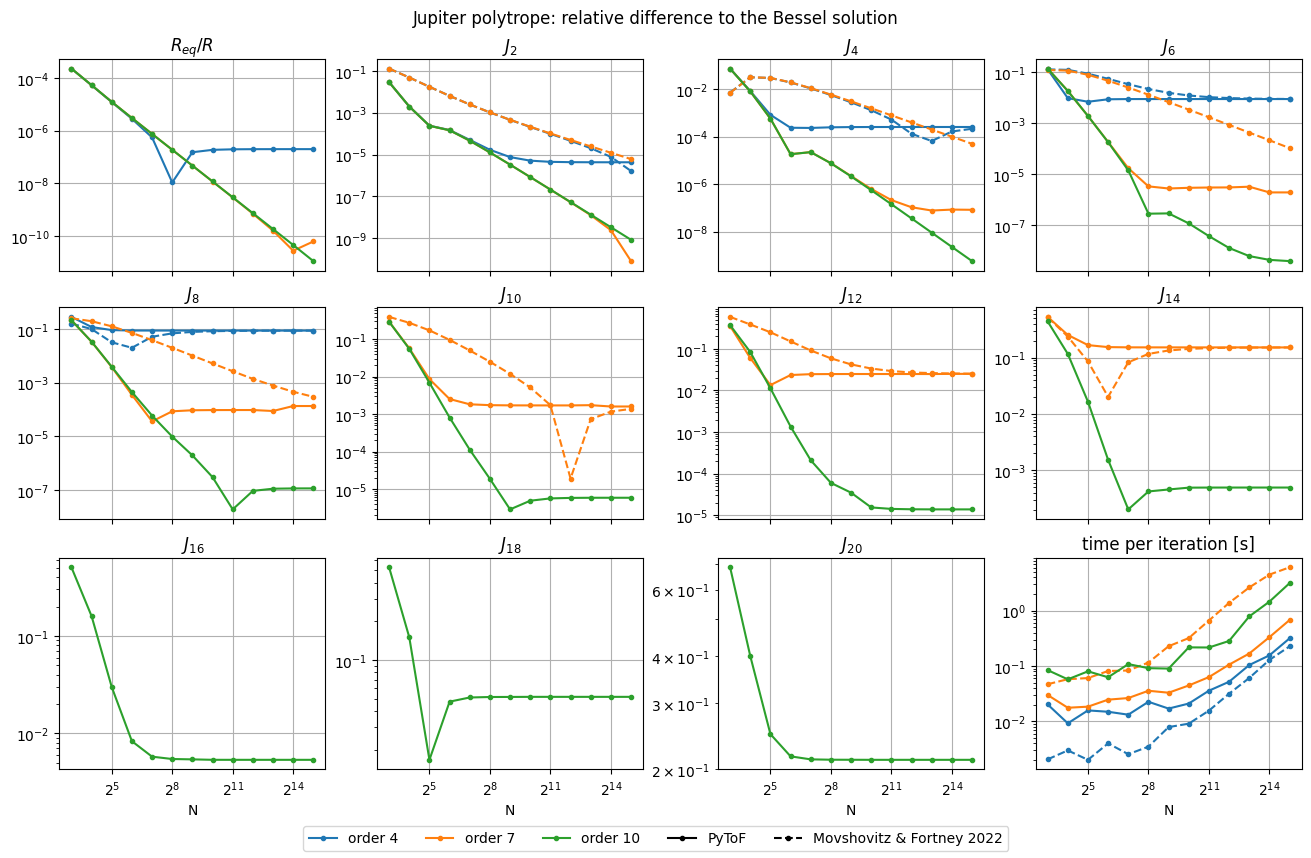

In [6]:
def fig_convergence(Ns, ref, ref_name, sweep, movs, path, title):
    import matplotlib.pyplot as plt

    fig, axs = plt.subplots(3, 4, figsize=(13, 8.5), layout="constrained", sharex=True)
    for i, ax in enumerate(axs.flat):
        for o in sweep:
            if i <= o:
                res = sweep[o]["res"][:, i, 0]
                y = res if np.isnan(ref[0]) and i == 0 else rel_err(res, ref[i])
                if not (i == 0 and np.isnan(ref[0])):
                    ax.plot(Ns, y, "o-", ms=3, color=COLORS[o])
                if movs and o in movs and 0 < i < movs[o]["res"].shape[1] and not np.isnan(ref[i]):
                    ax.plot(
                        Ns, rel_err(movs[o]["res"][:, i], ref[i]), "o--", ms=3, color=COLORS[o]
                    )
        if i < 11:
            ax.set_title(J_LABELS[i])
            if not np.isnan(ref[i]):
                ax.set_yscale("log")
        else:
            for o in sweep:
                ax.plot(Ns, sweep[o]["time"][:, 0], "o-", ms=3, color=COLORS[o])
                if movs and o in movs:
                    ax.plot(Ns, movs[o]["time"], "o--", ms=3, color=COLORS[o])
            ax.set_title("time per iteration [s]")
            ax.set_yscale("log")
        ax.set_xscale("log", base=2)
        ax.grid()
        if i >= 8:
            ax.set_xlabel("N")
    # one legend for the whole figure, below the panels: colour = order, line style = code
    from matplotlib.lines import Line2D

    handles = [Line2D([], [], color=COLORS[o], marker="o", ms=3, label=f"order {o}") for o in sweep]
    handles.append(Line2D([], [], color="k", marker="o", ms=3, label="PyToF"))
    if movs:
        handles.append(Line2D([], [], color="k", ls="--", marker="o", ms=3, label="Movshovitz & Fortney 2022"))
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    fig.suptitle(f"{title}: relative difference to {ref_name}")
    if path is not None:
        fig.savefig(path)
    plt.show()

movs = None
if FULL:
    movs = {o: dict(res=np.array([R[("mf", o, i)][1] for i in range(len(Ns))]),
                    time=np.array([R[("mf", o, i)][0] for i in range(len(Ns))])) for o in (4, 7)}
fig_convergence(Ns_f, ref, "the Bessel solution", simp, movs,
                IMAGES / "convergence_bessel.png" if SAVE_FIGURES else None, "Jupiter polytrope")

### Binning and cost (full mode)

`n_bin < N` computes the figure functions on `n_bin` points and interpolates. The heat maps show the error as a function of $N$ and the binning factor: a modest factor costs no accuracy (the colour stays the same along a row) and saves time at large $N$; for large factors the interpolation error dominates. The second figure shows every $(N, \text{binning})$ point against its cost; the line is the best error reachable within a time budget, i.e. what to choose for a given budget.

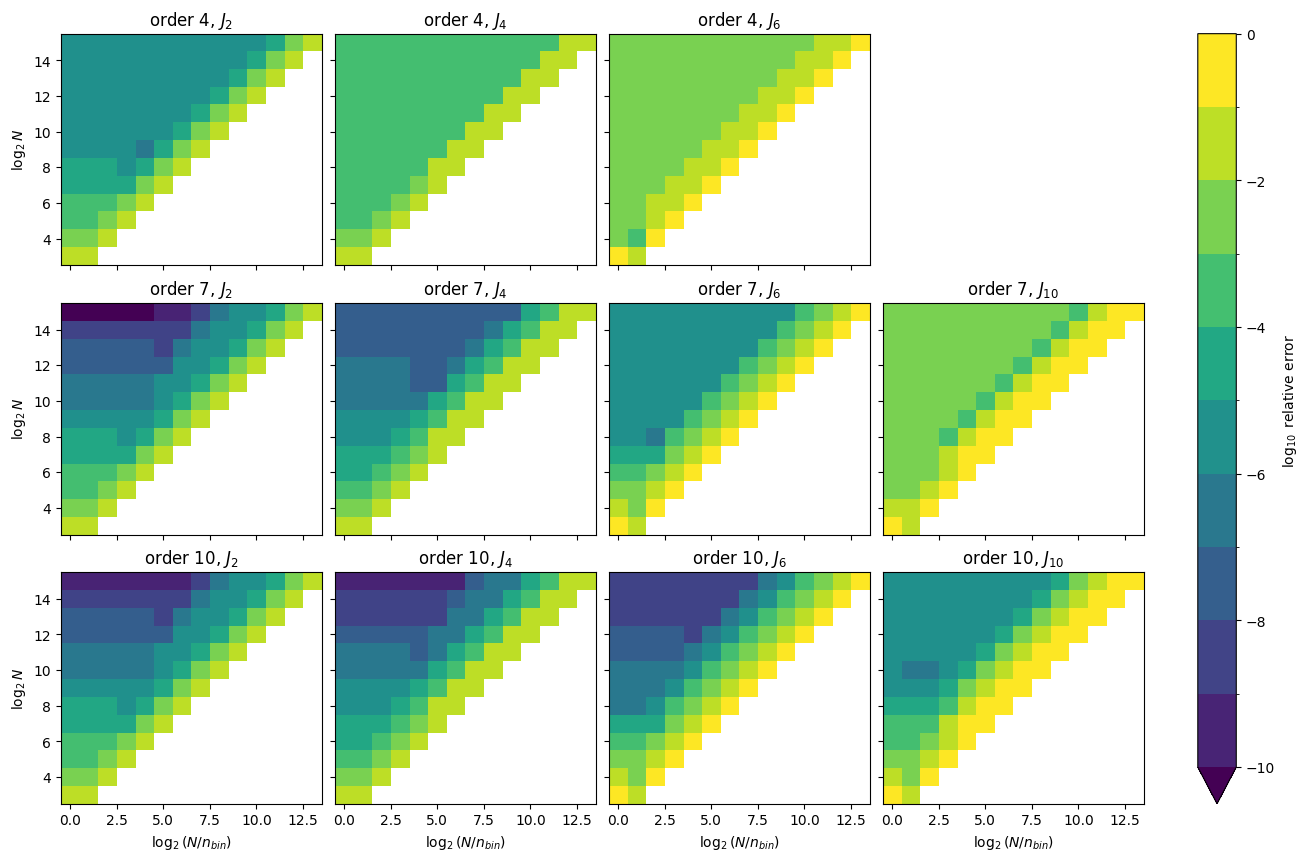

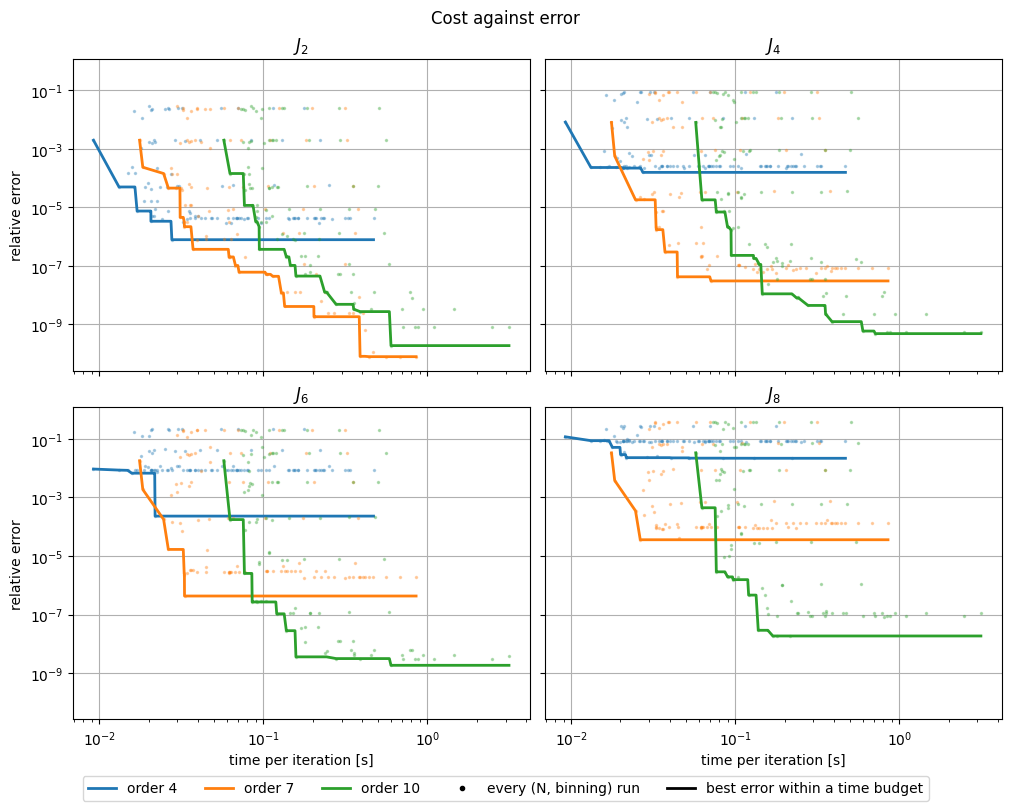

In [7]:
def fig_binning(Ns, steps, sweep, path):
    import matplotlib
    import matplotlib.pyplot as plt

    js = (1, 2, 3, 5)
    fig, axs = plt.subplots(3, len(js), figsize=(13, 8.5), layout="constrained", sharex=True, sharey=True)
    extent = [np.log2(steps[0]) - 0.5, np.log2(steps[-1]) + 0.5, np.log2(Ns[0]) - 0.5, np.log2(Ns[-1]) + 0.5]
    # discrete colours: one per decade of the relative error (+ one for everything below 1e-10)
    cmap = plt.get_cmap("viridis", 11)
    norm = matplotlib.colors.BoundaryNorm(np.arange(-10, 1), cmap.N, extend="min")
    for r, o in enumerate(ORDERS):
        for c, j in enumerate(js):
            ax = axs[r, c]
            if j > o:
                ax.axis("off")
                continue
            e = np.log10(rel_err(sweep[o]["res"][:, j, :], references.Bessel[j]))
            im = ax.imshow(e, origin="lower", aspect="auto", extent=extent, cmap=cmap, norm=norm)
            ax.set_title(rf"order {o}, $J_{{{2 * j}}}$")
            if r == 2:
                ax.set_xlabel(r"$\log_2(N/n_{bin})$")
            if c == 0:
                ax.set_ylabel(r"$\log_2 N$")
    fig.colorbar(im, ax=axs, label=r"$\log_{10}$ relative error", ticks=np.arange(-10, 1, 2))
    if path is not None:
        fig.savefig(path)
    plt.show()


def fig_work_precision(sweep, path):
    """Error against cost, every (N, binning) point; the lower-left envelope is the best setting per error."""
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    js = (1, 2, 3, 4)
    fig, axs = plt.subplots(2, 2, figsize=(10, 8), layout="constrained", sharex=True, sharey=True)
    for c, (j, ax) in enumerate(zip(js, axs.flat, strict=True)):
        for o in ORDERS:
            if j > o:
                continue
            t = sweep[o]["time"].ravel()
            e = rel_err(sweep[o]["res"][:, j, :], references.Bessel[j]).ravel()
            ok = np.isfinite(t) & np.isfinite(e) & (e > 0)
            t, e = t[ok], e[ok]
            ax.plot(t, e, ".", ms=3, alpha=0.3, color=COLORS[o])
            idx = np.argsort(t)
            best = np.minimum.accumulate(e[idx])
            ax.plot(t[idx], best, "-", lw=2, color=COLORS[o], label=f"order {o}")
        ax.set(xscale="log", yscale="log", title=rf"$J_{{{2 * j}}}$")
        ax.grid()
        if c % 2 == 0:
            ax.set_ylabel("relative error")
        if c >= 2:
            ax.set_xlabel("time per iteration [s]")
        if c == 0:
            handles, labels = ax.get_legend_handles_labels()
    handles += [Line2D([], [], color="k", marker=".", ls="", label="every (N, binning) run"),
                Line2D([], [], color="k", lw=2, label="best error within a time budget")]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles))
    fig.suptitle("Cost against error")
    if path is not None:
        fig.savefig(path)
    plt.show()

if FULL:
    fig_binning(Ns_f, steps, simp, IMAGES / "binning.png" if SAVE_FIGURES else None)
    fig_work_precision(simp, IMAGES / "work_precision.png" if SAVE_FIGURES else None)
else:
    print("(binning and cost figures: full mode only)")

## 3 · Differential rotation

With barotropic differential rotation (`alphas`) there is no exact solution. Wisdom & Hubbard (2016) give results of the CMS method for the wind profiles DR2 (four parameters) and DR3 (ten parameters), an independent method with its own numerical error, which for the higher moments is larger than that of PyToF; the curves flatten where the *reference* stops converging (DR3 is noisy beyond $J_{14}$). Up to $J_6$ all orders agree with CMS to $\sim10^{-4}$; the $5\times10^{-5}$ in $J_2$ is the same for all orders and $N$, i.e. not a truncation effect of PyToF (it may stem from the CMS reference).

relative difference to CMS, J_2 ... J_12
DR2, N = 32768
  order  4: 5.3e-05 1.6e-04 1.1e-02 8.3e-02
  order  7: 5.2e-05 9.8e-05 2.2e-04 3.3e-03 4.0e-03 4.3e-02
  order 10: 5.2e-05 9.7e-05 1.3e-04 1.7e-04 4.7e-04 8.4e-04
DR3, N = 32768
  order  4: 3.0e-05 1.9e-04 1.2e-02 7.0e-02
  order  7: 2.7e-05 5.0e-05 2.1e-04 4.1e-03 1.4e-03 1.4e+00
  order 10: 4.8e-05 8.7e-05 1.2e-04 3.5e-04 2.1e-03 1.4e-02


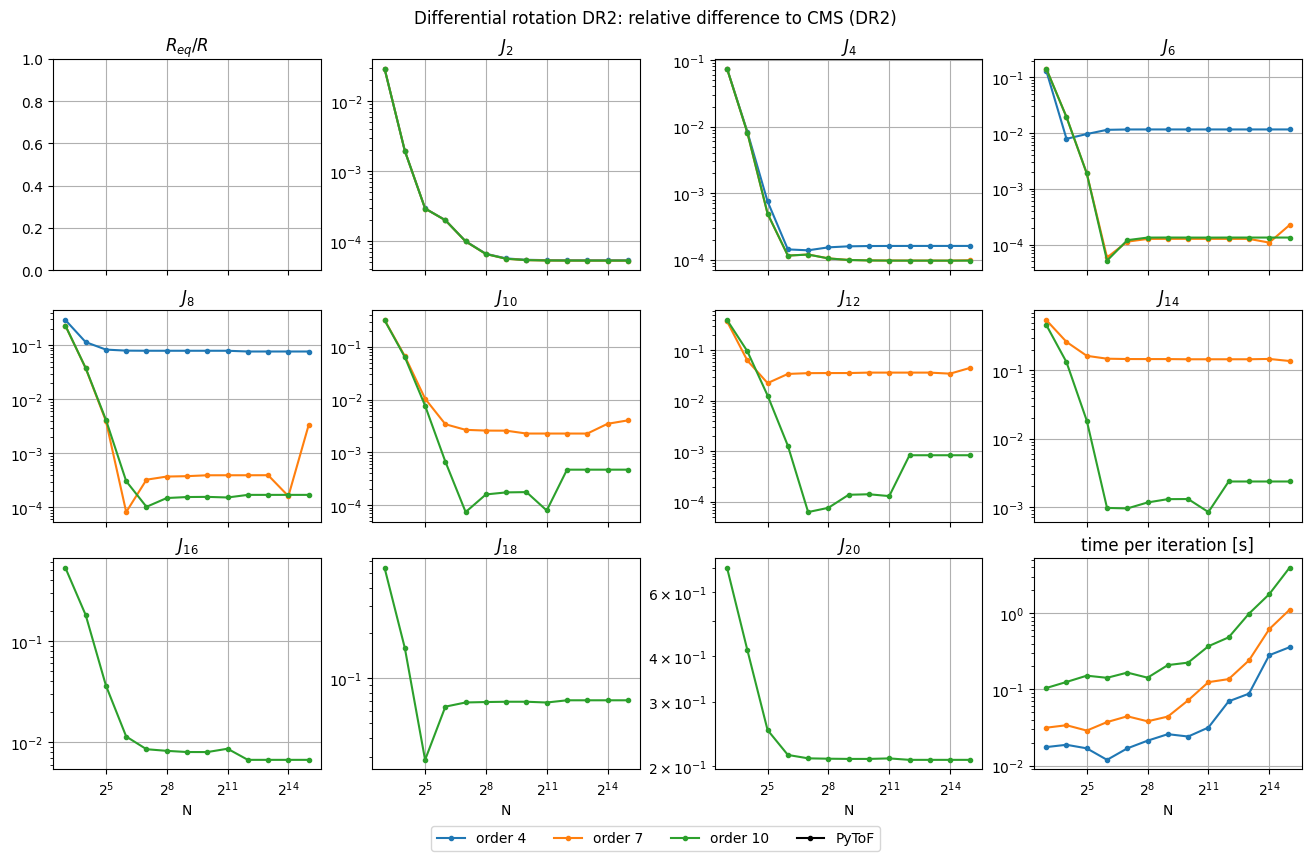

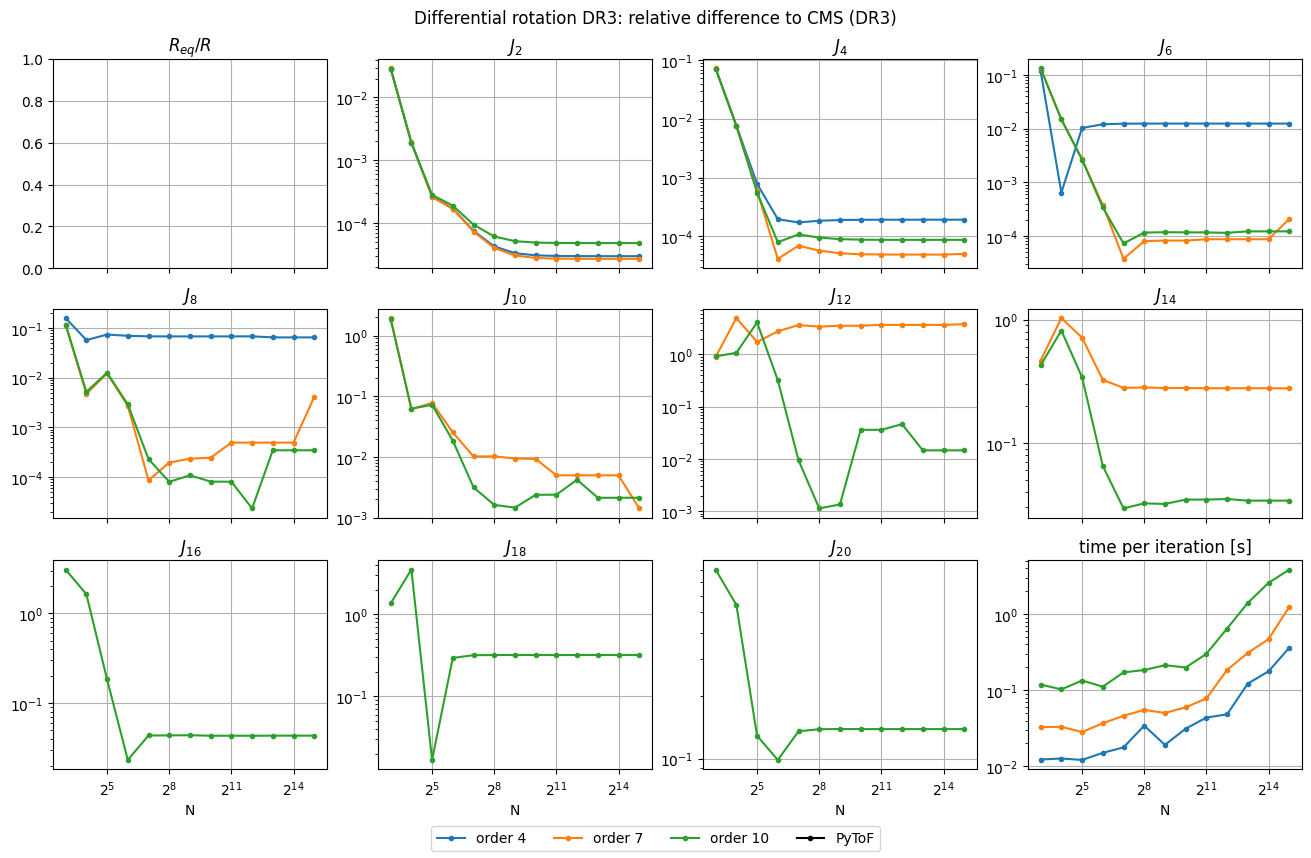

In [8]:
print("relative difference to CMS, J_2 ... J_12")
if FULL:
    drs = {"DR2": (references.CMSDR2, collect(R, Ns, steps[:1], ORDERS, "DR2")),
           "DR3": (references.CMSDR3, collect(R, Ns, steps[:1], ORDERS, "DR3"))}
    for name, (cms, sw) in drs.items():
        print(f"{name}, N = {Ns[-1]}")
        for o in ORDERS:
            r = sw[o]["res"][-1, :, 0]
            print(f"  order {o:2d}: " + " ".join(f"{abs(r[n] / cms[n] - 1):.1e}" for n in range(1, min(o, 6) + 1)))
    for name, (cms, sw) in drs.items():
        fig_convergence(Ns_f, cms, f"CMS ({name})", sw, None,
                        IMAGES / f"convergence_{name.lower()}.png" if SAVE_FIGURES else None,
                        f"Differential rotation {name}")
else:
    print("DR2, N = 2048")
    for o in ORDERS:
        r = R[("dr2", o)][1]
        print(f"  order {o:2d}: " + " ".join(f"{abs(r[n] / references.CMSDR2[n] - 1):.1e}" for n in range(1, min(o, 6) + 1)))

## 4 · The shipped error tables are reproducible

`ToF.get_Js_errors()` looks up the tables `PyToF/accuracy_data_{simpson,trapezoid}.npz`. We compare them with this run: the largest relative deviation must be $0$ (or rounding size), otherwise the numerics changed since the tables were made. In full mode all entries ($N$ x binning x order, both integration rules) are compared; set `WRITE_TABLES = True` in the settings to regenerate the files after a deliberate change of the numerics.

In [9]:
tab_s = error_tables(Ns_f, steps, simp)
if FULL:
    tab_t = error_tables(Ns_f, steps, collect(R, Ns, steps, ORDERS, "trapezoid"))
    for name, tab in (("simpson", tab_s), ("trapezoid", tab_t)):
        print(f"{name:9s}: largest relative deviation over all N, binnings, orders: {compare_with_shipped(name, tab):.1e}")
    if WRITE_TABLES:
        for name, tab in (("simpson", tab_s), ("trapezoid", tab_t)):
            np.savez(ROOT / "PyToF" / f"accuracy_data_{name}.npz", **tab)
        print("wrote PyToF/accuracy_data_{simpson,trapezoid}.npz")
else:
    old = np.load(ROOT / "PyToF" / "accuracy_data_simpson.npz")
    worst = 0.0
    for o in ORDERS:  # tables: N = 2^3..2^15, binning index 0 = no binning
        for i, N in enumerate(Ns):
            iN = int(np.log2(N)) - 3
            worst = max(worst, float(np.max(np.abs(tab_s[f"rel_error_{KEYS[o]}"][i, :, 0] / old[f"rel_error_{KEYS[o]}"][iN, :, 0] - 1))))
    print(f"simpson, no binning, N = {Ns[0]}..{Ns[-1]}: largest relative deviation: {worst:.1e}")

simpson  : largest relative deviation over all N, binnings, orders: 0.0e+00
trapezoid: largest relative deviation over all N, binnings, orders: 0.0e+00
